# Microscopy Analysis

In [ ]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk==0.6.2 -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from cdk.analysis import cell as m

## Load data

In [2]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Overwriting drive_utils.py


In [3]:
# Set use_drive = True to download platemap.csv from Google Drive instead of using a local file.
# The Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://drive.google.com/file/d/1hoFPeTzKXBOsjwwMKm7BYozyFXJ9V3J5/view?usp=sharing",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    PLATEMAP_PATH = downloaded_paths["platemap.csv"]
else:
    PLATEMAP_PATH = "platemap.csv"

print(f"Platemap file: {PLATEMAP_PATH}")

Platemap file: data/platemap.csv


In [4]:
ZARR_URL = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/deGFP-GUV-PegNB-Soln_2026-09-28_17-44-06.899443.zarr"
PARQUET_URL = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/deGFP-GUV-PegNB-Soln_2026-09-28_17-44-06.899443.parquet"

data = m.load(PARQUET_URL, PLATEMAP_PATH) #, sample=5000)

## Check Cell Segmentation
Optionally check cells - - will take a few seconds since this reads from a zarr file! If you want faster, load the zarr specifically into this folder. Dont use a URL.



## Summary Plots

In [ ]:
_ = m.plot_qc(data, hue="Name") #facet="other_col"

AttributeError: module 'cdk.analysis.cell' has no attribute 'plot_qc'

/usr/local/lib/python3.13/dist-packages/cdk/analysis/cell/analysis.py:263: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(list(by))[value].quantile(list(QUANTILES)).unstack()


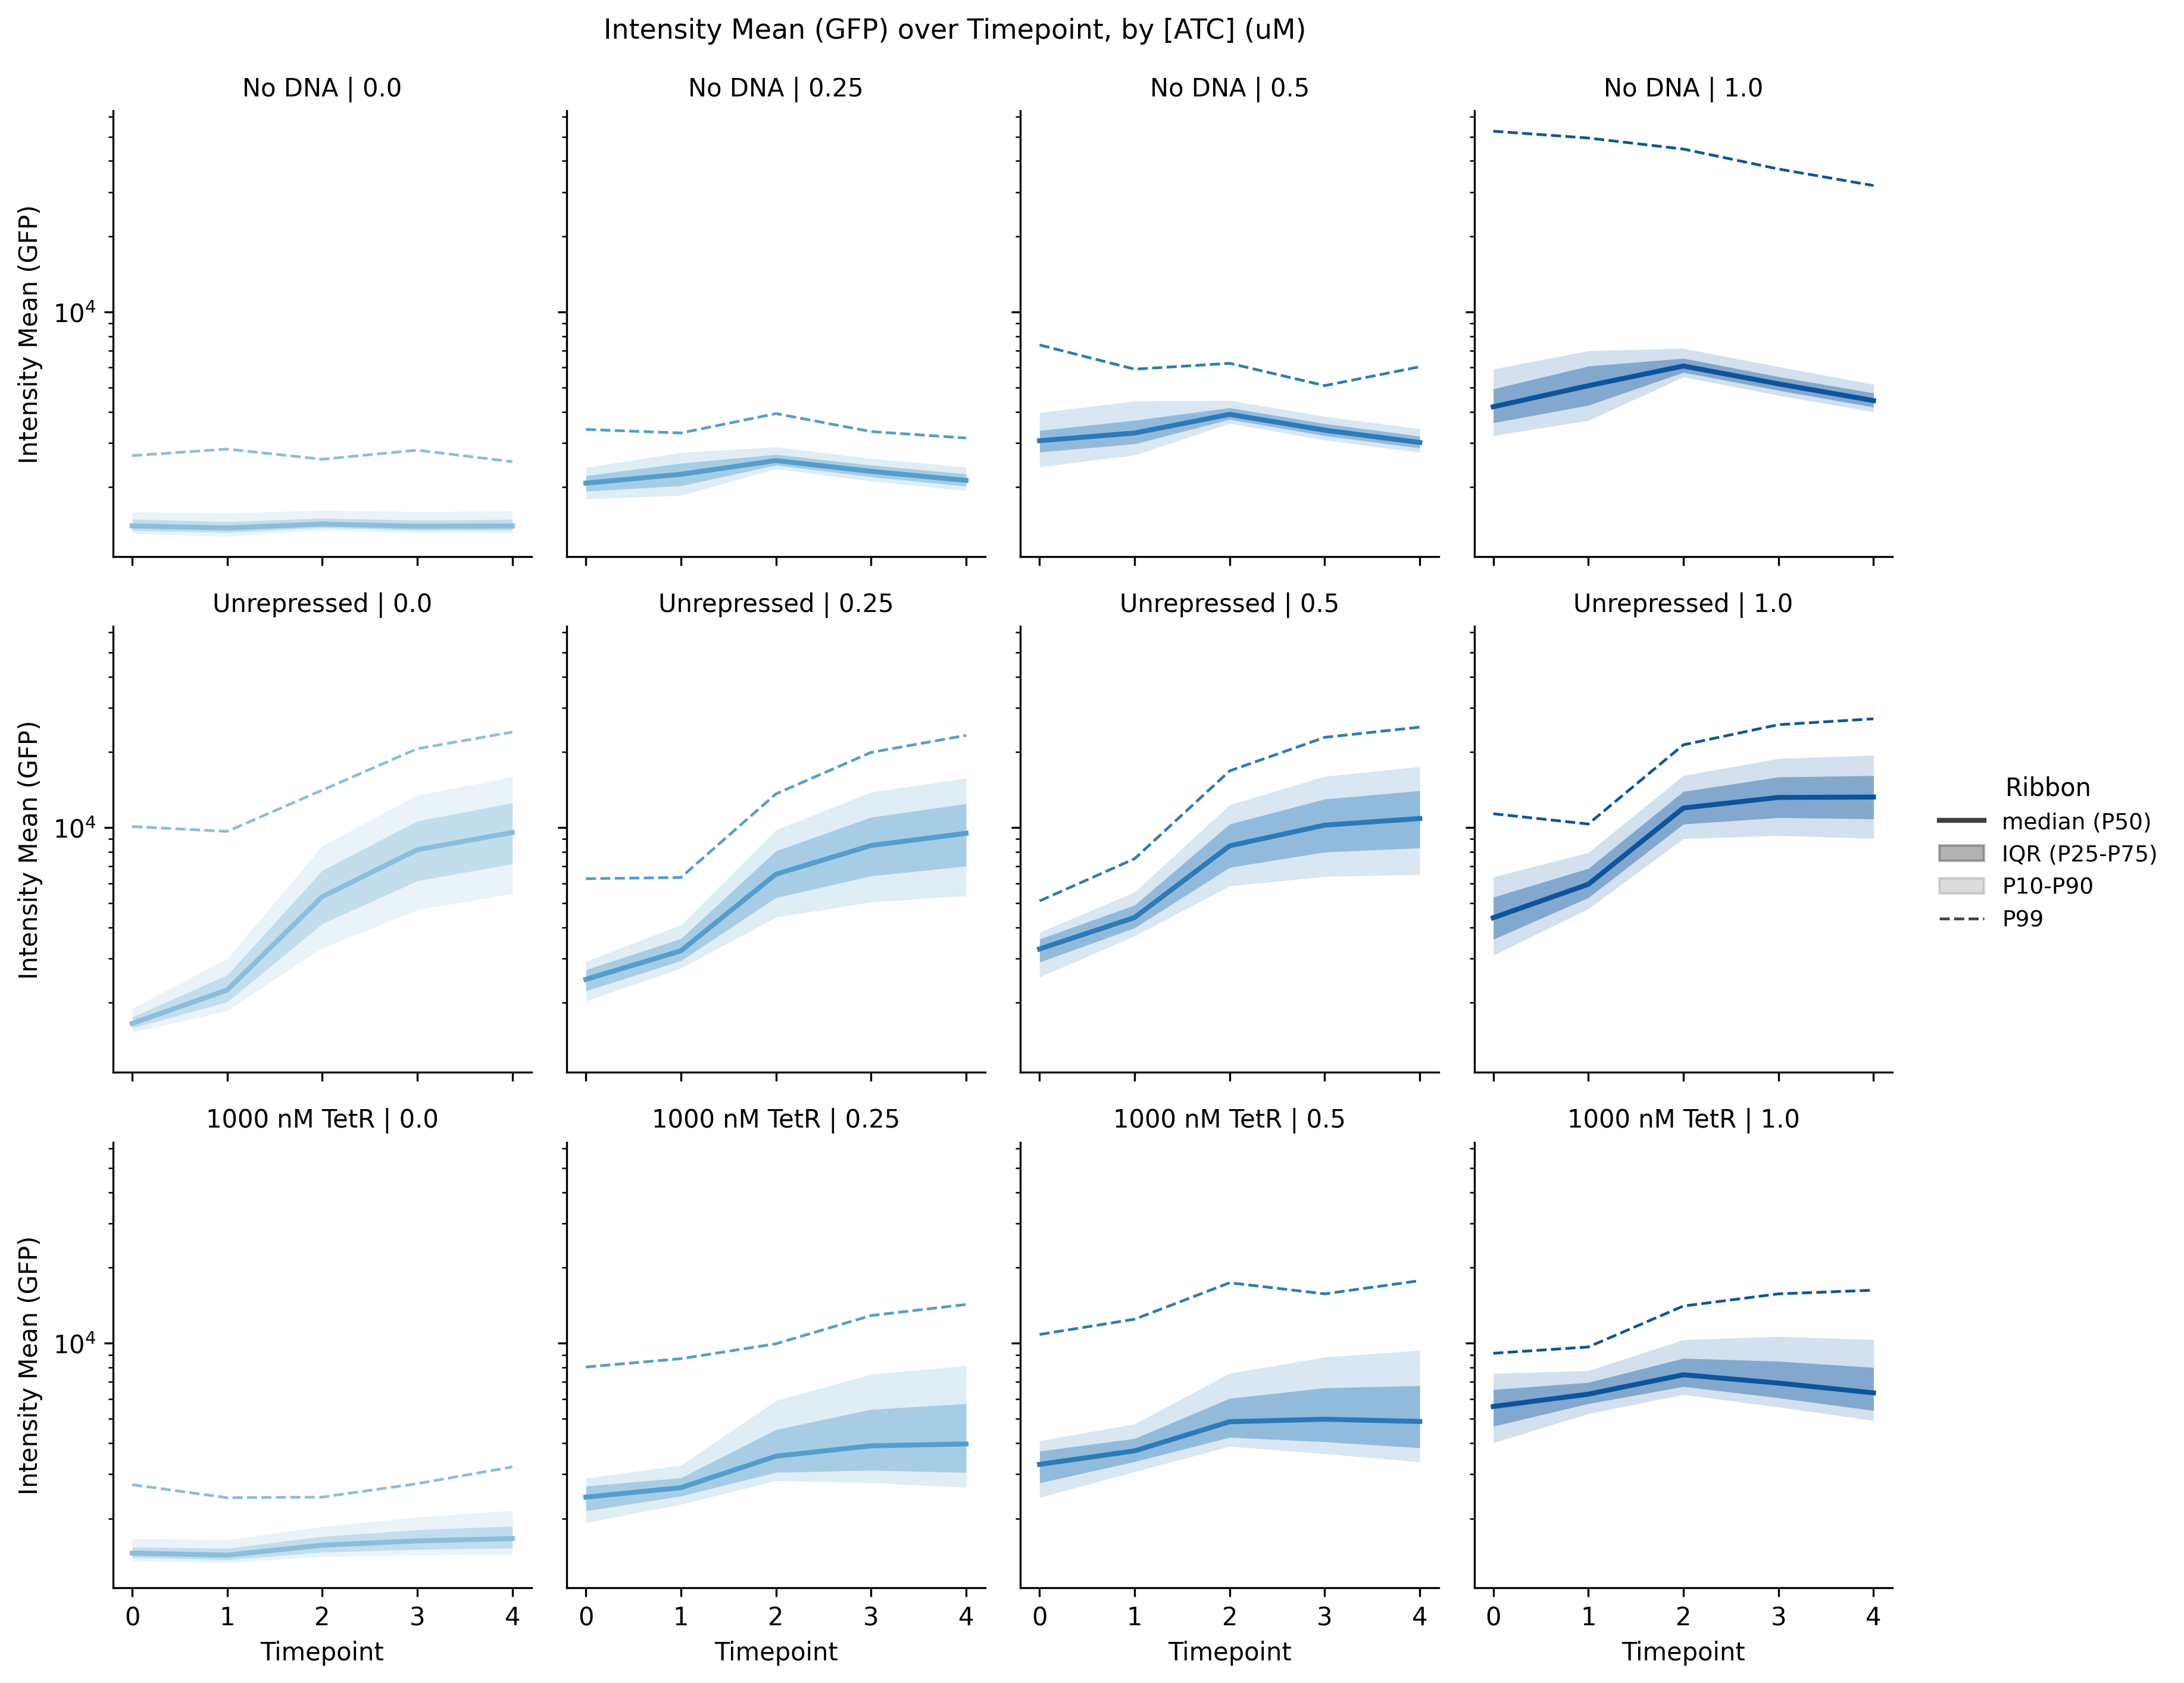

In [ ]:
#| label: mk-20260928-uscope
order = ["No DNA", "Unrepressed", "1000 nM TetR"]
solution = data[data["Format"] == "In solution"].copy()
solution["Condition"] = pd.Categorical(solution["Condition"], order, ordered=True)
_ = m.plot_quantile_ribbon(solution, hue="[ATC] (uM)", facet="Condition")

/usr/local/lib/python3.13/dist-packages/cdk/analysis/cell/analysis.py:263: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(list(by))[value].quantile(list(QUANTILES)).unstack()


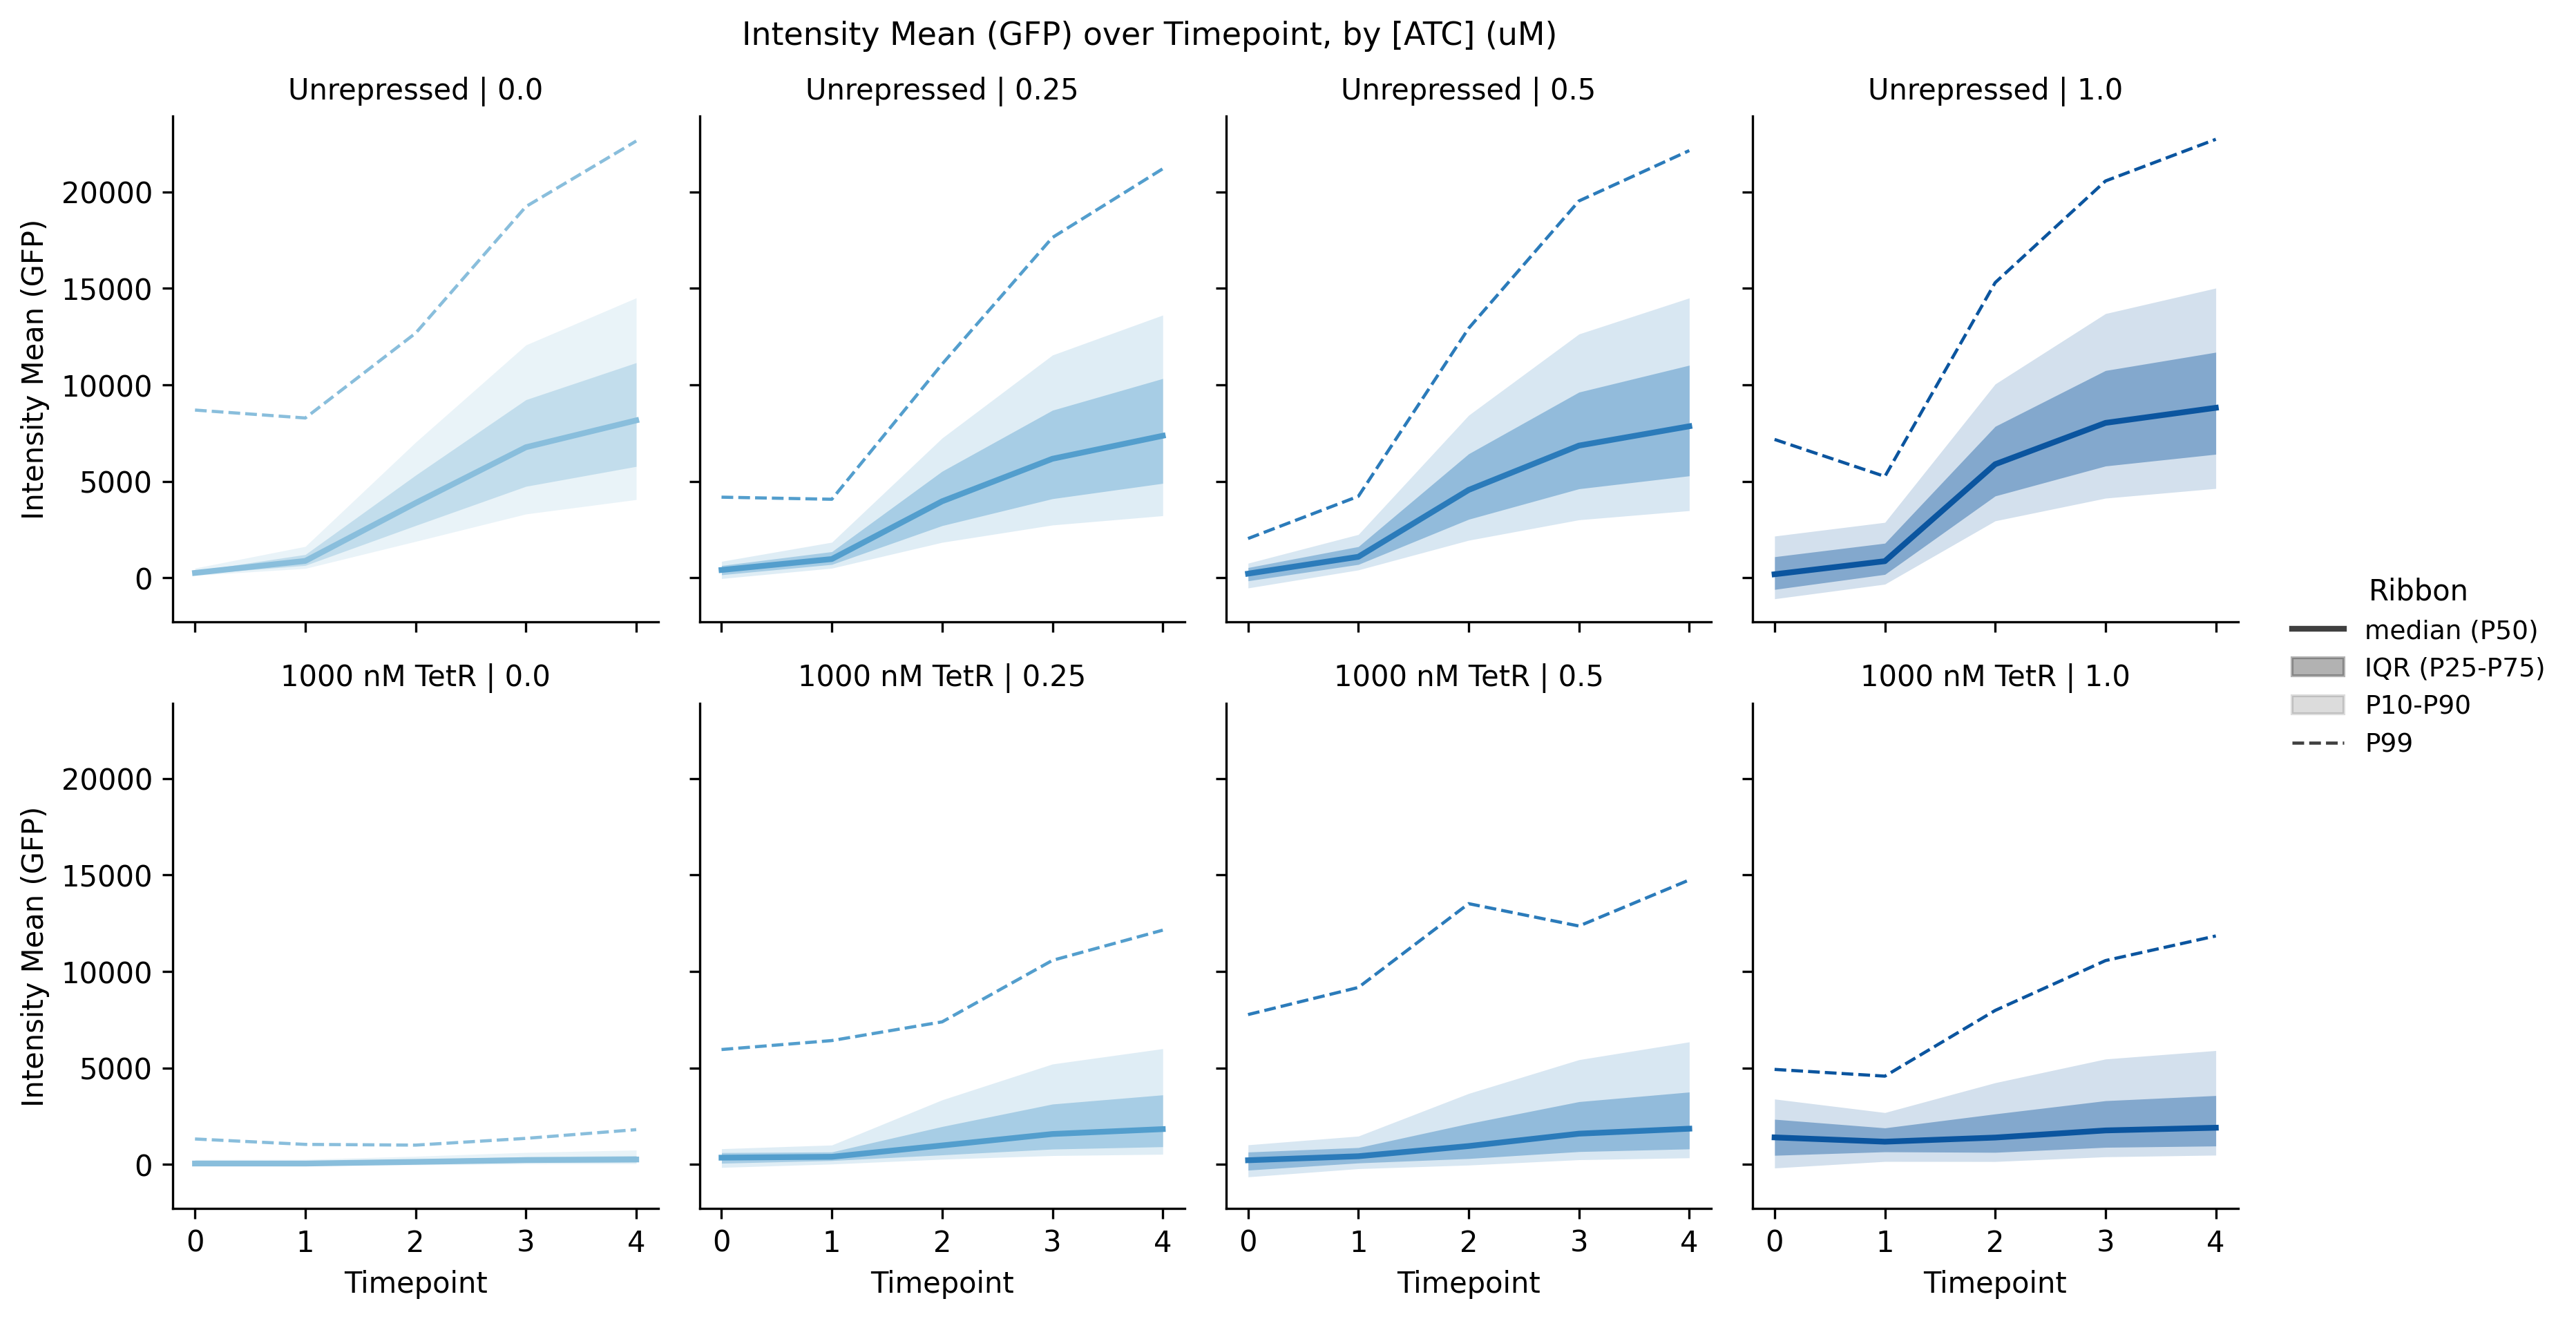

In [ ]:
#| label: mk-20260928-uscope-subtract-bkg
order = ["Unrepressed", "1000 nM TetR"]
value = m.intensity_column(data)      # "Intensity Mean (GFP)"
time = m.time_column(data)            # "Time (min)", else "Timepoint"
keys = ["Format", "[ATC] (uM)", time]

blank = (data[data["Condition"] == "No DNA"]
         .groupby(keys, as_index=False)[value]
         .median()
         .rename(columns={value: "background"}))

corrected = data.merge(blank, on=keys, how="left", validate="many_to_one")
corrected[value] = corrected[value] - corrected["background"]

solution = corrected[(corrected["Format"] == "In solution")
                     & (corrected["Condition"] != "No DNA")].copy()
solution["Condition"] = pd.Categorical(solution["Condition"], order, ordered=True)
_ = m.plot_quantile_ribbon(solution, hue="[ATC] (uM)", facet="Condition", logy=False)

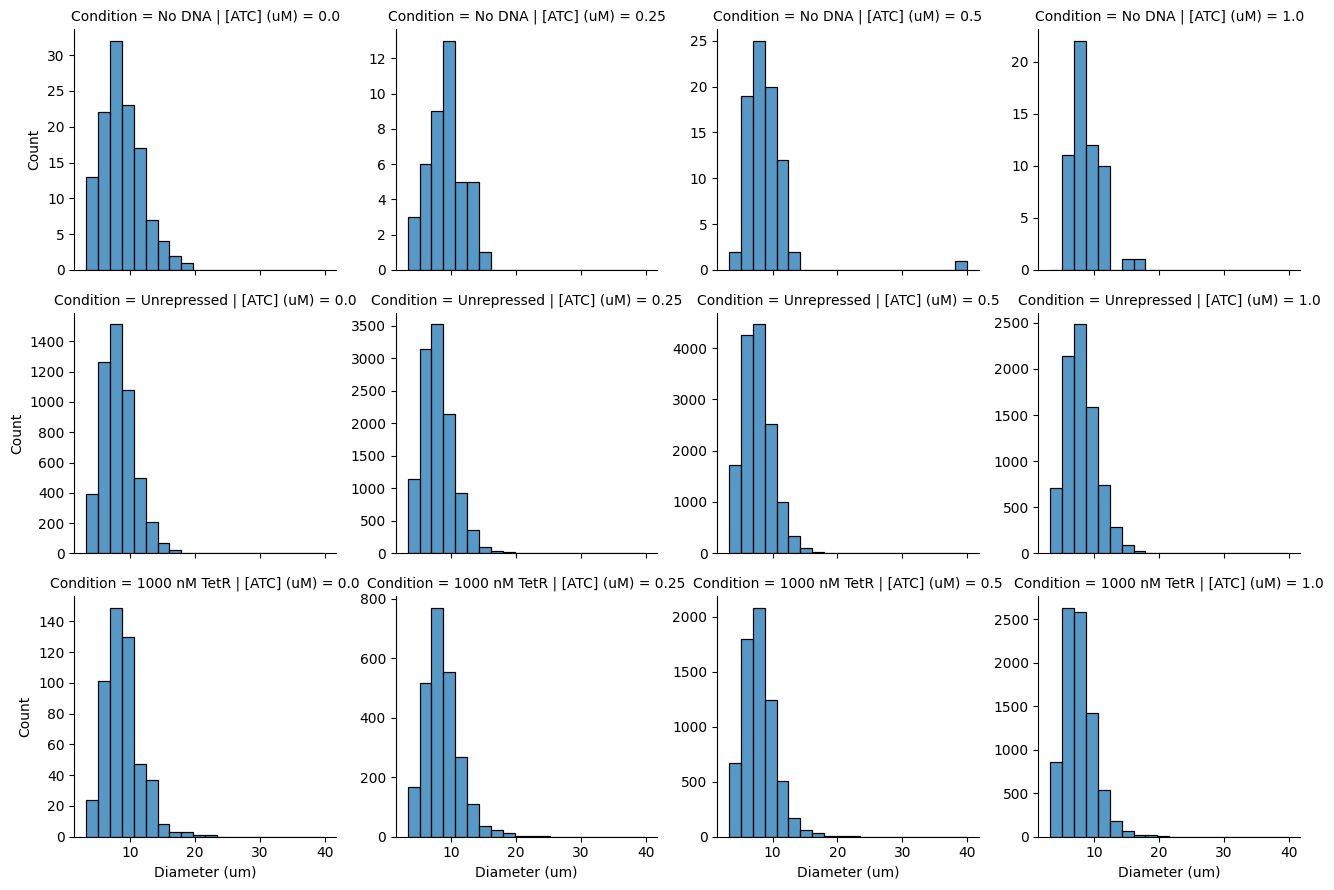

In [ ]:
value = m.intensity_column(data)
time = m.time_column(data)

sol = data[data["Format"] == "In solution"].copy()
sol["Condition"] = pd.Categorical(
    sol["Condition"], ["No DNA", "Unrepressed", "1000 nM TetR"], ordered=True)

gate = m.positive_gate(sol, value)
last = sol[sol[time] == sol[time].max()]
top = last[last[value] > last["Well"].map(gate)]

g = sns.displot(data=top, x=m.DIAMETER_COLUMN, row="Condition",
                col="[ATC] (uM)", bins=20, kind="hist",
                height=3.0, aspect=1.1, facet_kws={"sharey": False})
g.set_axis_labels("Diameter (um)", "Count")

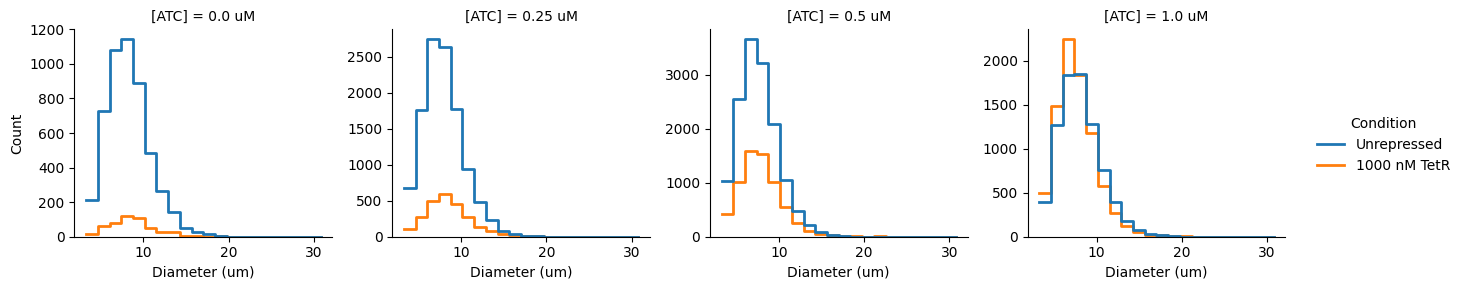

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

value = m.intensity_column(data)
time = m.time_column(data)

# in-solution droplets only
sol = data[data["Format"] == "In solution"].copy()

# gate to positives at the final timepoint
gate = m.positive_gate(sol, value)
last = sol[sol[time] == sol[time].max()]
top = last[last[value] > last["Well"].map(gate)].copy()

# just the two conditions, overlaid
top = top[top["Condition"].isin(["Unrepressed", "1000 nM TetR"])]
top["Condition"] = pd.Categorical(
    top["Condition"], ["Unrepressed", "1000 nM TetR"], ordered=True)

g = sns.displot(
    data=top,
    x=m.DIAMETER_COLUMN,
    hue="Condition",
    col="[ATC] (uM)",
    kind="hist",
    bins=20,
    element="step",
    fill=False,
    linewidth=2,
    common_bins=True,
    height=3.0,
    aspect=1.1,
    facet_kws={"sharey": False},
)
g.set_axis_labels("Diameter (um)", "Count")
g.set_titles("[ATC] = {col_name} uM")
plt.show()

/tmp/ipykernel_12017/1051993735.py:36: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=frac, x="[ATC] (uM)", y="Fraction positive",


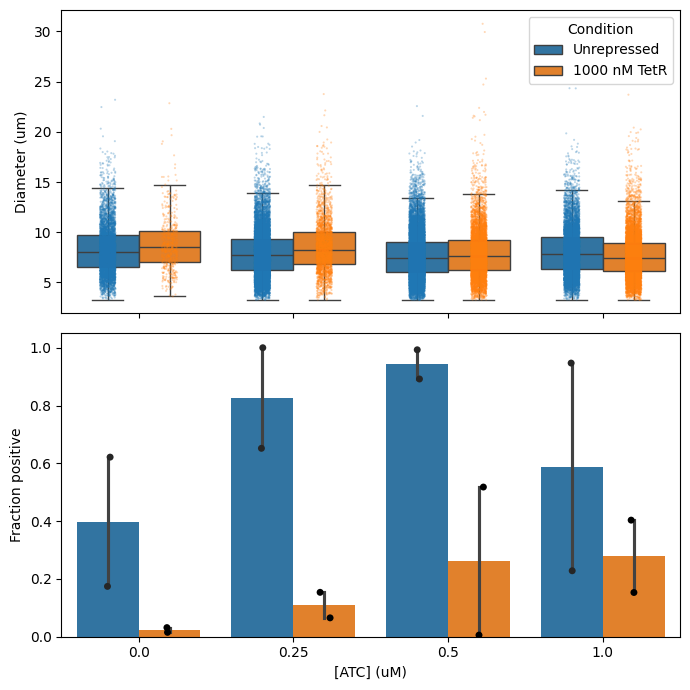

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

value = m.intensity_column(data)
time = m.time_column(data)

sol = data[data["Format"] == "In solution"].copy()
gate = m.positive_gate(sol, value)
last = sol[sol[time] == sol[time].max()]
top = last[last[value] > last["Well"].map(gate)].copy()

top = top[top["Condition"].isin(["Unrepressed", "1000 nM TetR"])]
top["Condition"] = pd.Categorical(
    top["Condition"], ["Unrepressed", "1000 nM TetR"], ordered=True)

# per-well fraction positive
totals = last.groupby("Well", observed=True).size()
frac = (top.groupby(["Well", "[ATC] (uM)", "Condition"], observed=True)
           .size().reset_index(name="n"))
frac["Fraction positive"] = frac["n"] / frac["Well"].map(totals)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# Panel A: diameter vs ATC
sns.boxplot(data=top, x="[ATC] (uM)", y=m.DIAMETER_COLUMN,
            hue="Condition", showfliers=False, ax=ax1)
sns.stripplot(data=top, x="[ATC] (uM)", y=m.DIAMETER_COLUMN,
              hue="Condition", dodge=True, size=1.5, alpha=0.3,
              legend=False, ax=ax1)
ax1.set_ylabel("Diameter (um)")

# Panel B: fraction positive vs ATC
sns.barplot(data=frac, x="[ATC] (uM)", y="Fraction positive",
            hue="Condition", ax=ax2)
sns.stripplot(data=frac, x="[ATC] (uM)", y="Fraction positive",
              hue="Condition", dodge=True, size=5, color="black",
              legend=False, ax=ax2)
ax2.set_ylabel("Fraction positive")
ax2.set_xlabel("[ATC] (uM)")
ax2.get_legend().remove()

plt.tight_layout()
plt.show()

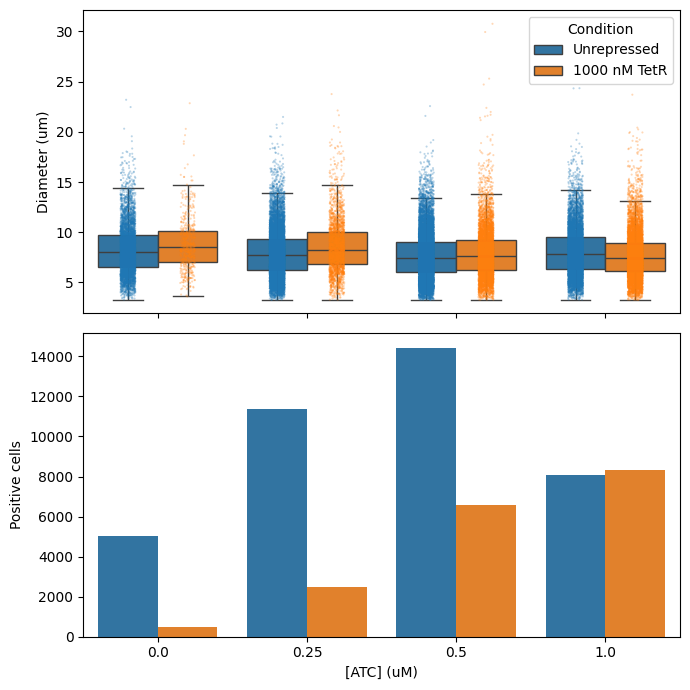

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

value = m.intensity_column(data)
time = m.time_column(data)

sol = data[data["Format"] == "In solution"].copy()
gate = m.positive_gate(sol, value)
last = sol[sol[time] == sol[time].max()]
top = last[last[value] > last["Well"].map(gate)].copy()

top = top[top["Condition"].isin(["Unrepressed", "1000 nM TetR"])]
top["Condition"] = pd.Categorical(
    top["Condition"], ["Unrepressed", "1000 nM TetR"], ordered=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# Panel A: diameter vs ATC
sns.boxplot(data=top, x="[ATC] (uM)", y=m.DIAMETER_COLUMN,
            hue="Condition", showfliers=False, ax=ax1)
sns.stripplot(data=top, x="[ATC] (uM)", y=m.DIAMETER_COLUMN,
              hue="Condition", dodge=True, size=1.5, alpha=0.3,
              legend=False, ax=ax1)
ax1.set_ylabel("Diameter (um)")

# Panel B: count vs ATC
counts = top.groupby(["[ATC] (uM)", "Condition"], observed=True).size().reset_index(name="Count")
sns.barplot(data=counts, x="[ATC] (uM)", y="Count", hue="Condition", ax=ax2)
ax2.set_ylabel("Positive cells")
ax2.set_xlabel("[ATC] (uM)")
ax2.get_legend().remove()

plt.tight_layout()
plt.show()

Kruskal-Wallis across 8 groups: H = 600.0, p = 2.444e-125

               Group A                Group B   n A   n B  median A  median B    diff  effect (rbc)  p_raw  p_adj sig
1000 nM TetR @ 0.25 uM   Unrepressed @ 0.5 uM  2467 14431    8.2706    7.3974  0.8731        0.2043 0.0000 0.0000 ***
1000 nM TetR @ 0.25 uM  1000 nM TetR @ 1.0 uM  2467  8310    8.2706    7.3974  0.8731        0.2056 0.0000 0.0000 ***
  Unrepressed @ 0.0 uM   Unrepressed @ 0.5 uM  5054 14431    8.0051    7.3974  0.6077        0.1418 0.0000 0.0000 ***
 1000 nM TetR @ 1.0 uM   Unrepressed @ 0.0 uM  8310  5054    7.3974    8.0051 -0.6077       -0.1416 0.0000 0.0000 ***
  Unrepressed @ 0.5 uM   Unrepressed @ 1.0 uM 14431  8066    7.3974    7.8232 -0.4258       -0.0995 0.0000 0.0000 ***
1000 nM TetR @ 0.25 uM  Unrepressed @ 0.25 uM  2467 11379    8.2706    7.6839  0.5867        0.1429 0.0000 0.0000 ***
1000 nM TetR @ 0.25 uM  1000 nM TetR @ 0.5 uM  2467  6577    8.2706    7.6369  0.6337        0.1503 0.0000 0.0000 *

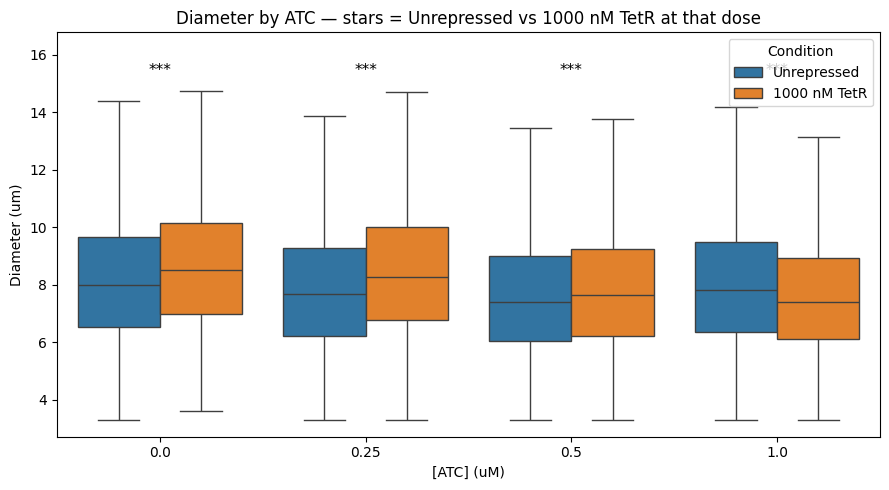

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations
from statsmodels.stats.multitest import multipletests

value = m.intensity_column(data)
time = m.time_column(data)

sol = data[data["Format"] == "In solution"].copy()
gate = m.positive_gate(sol, value)
last = sol[sol[time] == sol[time].max()]
top = last[last[value] > last["Well"].map(gate)].copy()

top = top[top["Condition"].isin(["Unrepressed", "1000 nM TetR"])]
top["Condition"] = pd.Categorical(
    top["Condition"], ["Unrepressed", "1000 nM TetR"], ordered=True)
top["Group"] = (top["Condition"].astype(str) + " @ "
                + top["[ATC] (uM)"].astype(str) + " uM")

D = m.DIAMETER_COLUMN
groups = {k: v[D].dropna().values for k, v in top.groupby("Group", observed=True)}
groups = {k: v for k, v in groups.items() if len(v) >= 3}

# ---- omnibus ----
H, p_omni = stats.kruskal(*groups.values())
print(f"Kruskal-Wallis across {len(groups)} groups: H = {H:.1f}, p = {p_omni:.3e}\n")

# ---- pairwise Mann-Whitney + Holm correction ----
rows = []
for a, b in combinations(groups, 2):
    x, y = groups[a], groups[b]
    U, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    # rank-biserial correlation: effect size, 0 = no shift, 1 = complete separation
    rbc = 2 * U / (len(x) * len(y)) - 1
    rows.append({"Group A": a, "Group B": b, "n A": len(x), "n B": len(y),
                 "median A": np.median(x), "median B": np.median(y),
                 "diff": np.median(x) - np.median(y),
                 "effect (rbc)": rbc, "p_raw": p})

res = pd.DataFrame(rows)
res["p_adj"] = multipletests(res["p_raw"], method="holm")[1]
res["sig"] = np.where(res["p_adj"] < 0.001, "***",
             np.where(res["p_adj"] < 0.01, "**",
             np.where(res["p_adj"] < 0.05, "*", "ns")))
res = res.sort_values("p_adj").round(4)

pd.set_option("display.width", 200, "display.max_rows", None)
print(res.to_string(index=False))

# ---- plot with within-ATC comparison annotated ----
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=top, x="[ATC] (uM)", y=D, hue="Condition",
            showfliers=False, ax=ax)
ax.set_ylabel("Diameter (um)")

lookup = {frozenset([r["Group A"], r["Group B"]]): r for _, r in res.iterrows()}
ymax = top[D].quantile(0.99)
for i, atc in enumerate(sorted(top["[ATC] (uM)"].unique())):
    key = frozenset([f"Unrepressed @ {atc} uM", f"1000 nM TetR @ {atc} uM"])
    if key in lookup:
        r = lookup[key]
        ax.text(i, ymax * 1.02, r["sig"], ha="center", fontsize=11)

ax.set_ylim(top=ymax * 1.12)
ax.set_title("Diameter by ATC — stars = Unrepressed vs 1000 nM TetR at that dose")
plt.tight_layout()
plt.show()